In [5]:
!apt-get update
!apt-get install -y libgmt-dev ghostscript gmt-dcw gmt-gshhg

!pip install harmonica pygmt boule

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libgmt-dev is already the newest version (6.5.0+dfsg-3build2).
ghostscript is already the newest version (10.02.1~dfsg1-0ubuntu7.8).
gmt-dcw is already the newest version

In [6]:
import harmonica as hm
import pygmt
import boule as bl
import numpy as np

In [7]:
malha = hm.load_icgem_gdf("geoide.gdf")
malha

<xarray.Dataset> Size: 6MB
Dimensions:    (latitude: 601, longitude: 1201)
Coordinates:
  * latitude   (latitude) float64 5kB -90.0 -89.7 -89.4 -89.1 ... 89.4 89.7 90.0
  * longitude  (longitude) float64 10kB -180.0 -179.7 -179.4 ... 179.7 180.0
Data variables:
    geoid      (latitude, longitude) float64 6MB -30.05 -30.05 ... 13.49 13.49
Attributes: (12/34)
    generating_institute:  gfz-potsdam
    generating_date:       2026/09/18
    product_type:          gravity_field
    body:                  earth
    modelname:             goco06s
    max_used_degree:       300
    ...                    ...
    maxvalue:              8.4332296E+01 meter
    minvalue:              -1.0736134E+02 meter
    signal_wrms:           3.0590376E+01 meter
    grid_format:           long_lat_value
    attributes:            longitude latitude geoid
    attributes_units:      deg. deg. meter

In [8]:
print(bl.WGS84)

WGS84 - World Geodetic System (1984)
Oblate ellipsoid:
  • Semimajor axis: 6378137 m
  • Flattening: 0.0033528106647474805
  • GM: 398600441800000.0 m³/s²
  • Angular velocity: 7.292115e-05 rad/s
Source:
  Hofmann-Wellenhof, B., & Moritz, H. (2006). Physical Geodesy (2nd,
    corr. ed. 2006 edition ed.). Wien; New York: Springer.


In [9]:
lon2d, lat2d = np.meshgrid(malha.longitude, malha.latitude)

gravidade_normal = bl.WGS84.normal_gravity(
    (lon2d, lat2d, malha.geoid)
)

gravidade_normal = malha.geoid.copy(data=gravidade_normal)

disturbio = malha.geoid - gravidade_normal
disturbio

/usr/local/lib/python3.13/dist-packages/boule/_ellipsoid.py:1240: UserWarning: Formulas used are valid for points outside the ellipsoid.Height must be greater than or equal to zero.
  warn(message, stacklevel=1)


<xarray.DataArray 'geoid' (latitude: 601, longitude: 1201)> Size: 6MB
array([[-983257.80873973, -983257.80873973, -983257.80873973, ...,
        -983257.80873973, -983257.80873973, -983257.80873973],
       [-983257.91124028, -983257.91386303, -983257.91649588, ...,
        -983257.90602531, -983257.90862762, -983257.91124028],
       [-983257.76709804, -983257.76935261, -983257.77165579, ...,
        -983257.76273461, -983257.76489214, -983257.76709804],
       ...,
       [-983200.26300007, -983200.26479736, -983200.26658533, ...,
        -983200.25937862, -983200.26119371, -983200.26300007],
       [-983200.84624254, -983200.84702734, -983200.84780751, ...,
        -983200.84466041, -983200.84545361, -983200.84624254],
       [-983200.84273149, -983200.84273149, -983200.84273149, ...,
        -983200.84273149, -983200.84273149, -983200.84273149]])
Coordinates:
  * latitude   (latitude) float64 5kB -90.0 -89.7 -89.4 -89.1 ... 89.4 89.7 90.0
  * longitude  (longitude) float64 10kB -180.0 -179.7 -179.4 ... 179.7 180.0

grdimage [WARNING]: Longitude range too small; geographic boundary condition changed to natural.


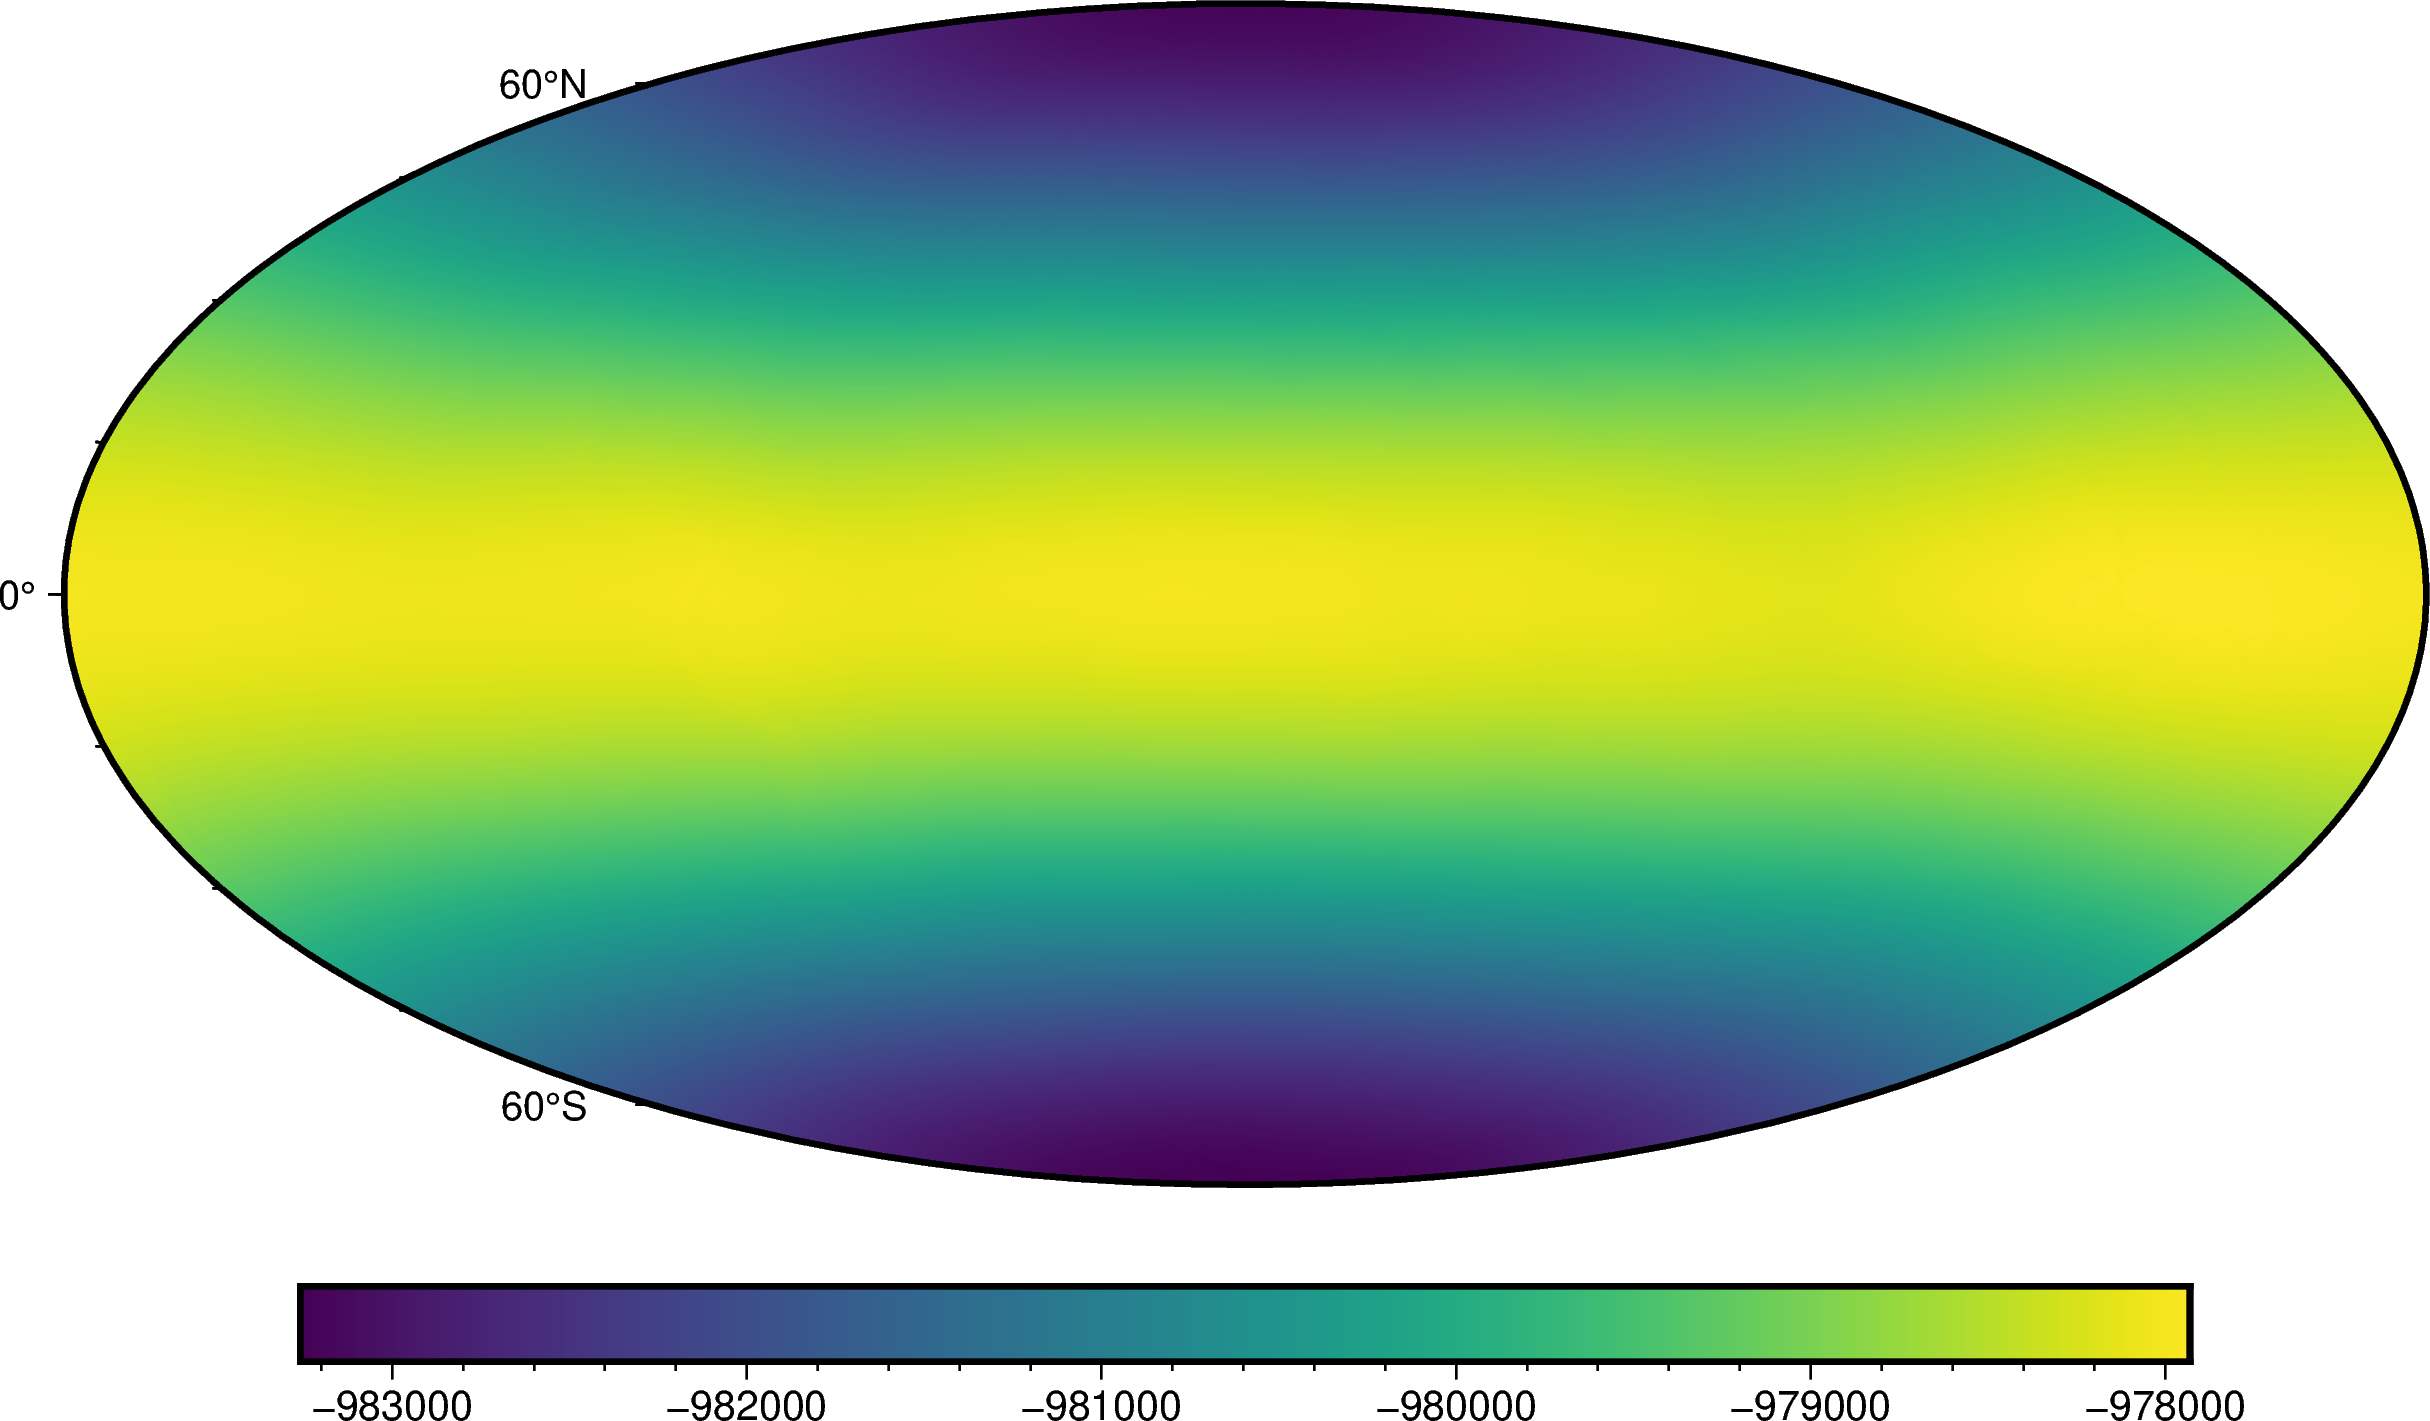

In [10]:
fig = pygmt.Figure()
fig.grdimage(disturbio, projection="H20c", cmap="viridis", frame=True)
fig.colorbar()
fig.show()